# 01 · Datos y análisis exploratorio (EDA)

**SIRAP** · Proyecto Integrador en IA (MIAR0545) · Eduardo Alejandro Ceballos Jijón · Christian Xavier Valle Maridueña

Descarga el dataset de detección (Roboflow v11), cuenta imágenes y placas por split, clasifica las placas de *test* por tamaño y dibuja ejemplos con sus etiquetas (1.1 y 1.2). Extrae además los recortes de SAVH Guayaquil con los que se evalúa el OCR y explica por qué su referencia necesita corrección (1.3). El análisis escrito está en `docs/analisis_datos.md`.

> Este notebook es un extracto de `SIRAP_backend.ipynb` (el notebook completo, que es la fuente de verdad). Las celdas y sus salidas son las mismas y conservan la numeración de secciones del notebook completo; la sección 0 se repite para que corra por sí solo en Colab.


## 0. Preparación del entorno

Esta sección deja lista la sesión de Colab: comprueba la GPU, instala las librerías, lee las llaves de API, monta Google Drive, define todas las rutas de entrada y fija la configuración del experimento. Hay que correrla completa al empezar cada sesión; no entrena ni evalúa nada.

### GPU
`nvidia-smi` muestra la GPU asignada. Si falla, ve a `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → `GPU T4` y guarda. Sin GPU el notebook funciona, pero entrenar y evaluar el detector se vuelve muy lento (el OCR corre en la CPU en cualquier caso).

In [ ]:
!nvidia-smi

Sat Oct 24 00:16:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   33C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Dependencias
Instala solo las librerías que Colab no trae, en las versiones con las que se probó el notebook, para que los resultados se puedan reproducir:

- `ultralytics==8.4.177`: entrenamiento, validación e inferencia de YOLO11.
- `trackers==2.6.1`: OC-SORT, el seguidor de placas del pipeline de video.
- `supervision==0.30.9`: detecciones, anotación de video y mAP por tamaño de placa.
- `fast-plate-ocr==1.1.0` y `onnxruntime==1.31.0`: el OCR de placas (`cct-s-v2-global-model`) y el motor que lo corre en la CPU. fast-plate-ocr se instala sin sus dependencias (`--no-deps`): pide `opencv-python-headless`, que podría chocar con el `opencv-python` de Colab (dos paquetes para el mismo `cv2`), y las demás (`numpy`, `pyyaml`, `rich` y `tqdm`) ya vienen en Colab.
- `roboflow==1.7.1`: descarga del dataset.
- `Levenshtein`: distancia entre placas (regla de decisión y CER).
- `psycopg[binary]==3.3.6`: conexión con PostgreSQL, donde se carga la base de datos de la planta.

`torch`, `torchvision`, `opencv`, `pandas` y `matplotlib` ya vienen en Colab y no se tocan. Si al terminar Colab pide **reiniciar la sesión**, reinicia y sigue desde la celda siguiente (no hace falta reinstalar).

La celda de importaciones, más abajo, carga todas las librerías y muestra la GPU y las versiones instaladas.

In [ ]:
!pip install -q "ultralytics==8.4.177" "trackers==2.6.1" "supervision==0.30.9" "roboflow==1.7.1" Levenshtein "psycopg[binary]==3.3.6" "onnxruntime==1.31.0"
!pip install -q --no-deps "fast-plate-ocr==1.1.0"  # sin dependencias: usa el OpenCV que ya trae Colab

### Llaves de API (*Secrets* de Colab)

Las llaves no se escriben en el notebook: la función `get_secret` las lee del panel 🔑 **Secrets** de Colab (fuera de Colab, de variables de entorno).

| Secret | Para qué | ¿Obligatorio? |
|---|---|---|
| `ROBOFLOW_API_KEY` | Descargar el dataset de placas desde Roboflow (Roboflow → `Settings` → `API`) | Sí, con `DATASET_SOURCE = "roboflow"` |
| `PG_DSN` | Usar un servidor PostgreSQL propio (por ejemplo Supabase o Neon) en lugar del que el notebook instala en Colab | No (sección 6.3) |
| `CAMARA_URL` | Dirección de la cámara para el modo en vivo: la del túnel de Cloudflare (`https://….trycloudflare.com`) | No (sección 9) |
| `CAMARA_TOKEN` | Token que imprime `puente_camara.py` en la PC de la cámara | Con el puente (sección 9) |
| `CF_ACCESS_CLIENT_ID` y `CF_ACCESS_CLIENT_SECRET` | Token de servicio, si el túnel está protegido con Cloudflare Access | No (sección 9) |

En Colab: panel izquierdo → 🔑 **Secrets** → agrega cada nombre con su valor y activa el acceso desde el notebook.

> ⚠️ Una versión anterior de este notebook tenía dos llaves de Roboflow escritas en celdas, así que quedaron guardadas en ese archivo y en cualquier copia que se haya compartido. **Revócalas en Roboflow (`Settings` → `API`), genera una nueva** y usa solo el *Secret*.

In [ ]:
import os


def get_secret(name: str, required: bool = False):
    """Lee un secreto de Colab (panel 🔑) o, fuera de Colab, de una variable de entorno."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
    except ImportError:
        value = os.environ.get(name)
    except Exception:  # el secreto no existe o el notebook no tiene acceso
        value = None
    if required and not value:
        raise RuntimeError(f"Falta el secreto {name}: agrégalo en el panel 🔑 Secrets de Colab.")
    return value

In [ ]:
import csv
import copy
import gc
import hashlib
import json
import random
import re
import shutil
import subprocess
import time
import urllib.request
import zipfile
from importlib.metadata import version
from math import comb
from pathlib import Path

import cv2
import Levenshtein
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import yaml
from IPython.display import Image as IPyImage, Video, display
from PIL import Image, ImageDraw, ImageFont
from supervision.metrics import MeanAveragePrecision
from tqdm.auto import tqdm
from trackers import OCSORTTracker
from ultralytics import YOLO
from ultralytics.data.utils import IMG_FORMATS
from ultralytics.utils.torch_utils import get_flops, get_num_params

CUDA = torch.cuda.is_available()
DEVICE = 0 if CUDA else "cpu"
FP16 = 16 if CUDA else None  # inferencia en FP16 en la GPU (argumento `quantize` de Ultralytics 8.4)

print("GPU:", torch.cuda.get_device_name(0) if CUDA else "no disponible: todo será muy lento")
for package in ["torch", "ultralytics", "trackers", "supervision", "fast-plate-ocr", "onnxruntime"]:
    print(f"{package:<16}{version(package)}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: NVIDIA L4
torch           2.11.0+cu130
ultralytics     8.4.177
trackers        2.6.1
supervision     0.30.9
fast-plate-ocr  1.1.0
onnxruntime     1.31.0


### Carpeta de trabajo en Google Drive
Colab borra `/content` al cerrar la sesión y entrenar el detector toma tiempo, así que todo se guarda en `MyDrive/proyecto_integrador_placas`. Si la sesión se cae a mitad de un entrenamiento, al volver a correr la celda de ese modelo **se reanuda desde la última época guardada**; y los resultados finales (sección 8) se pueden correr en otra sesión, porque lee todo desde aquí.

La celda siguiente monta Drive, define **todas** las rutas de entrada en un solo lugar y al final muestra cuáles encontró (`ok`, `vacío` o `no está`). Las que faltan no detienen el notebook: la sección que usa cada una se salta.

| Ruta en `MyDrive/proyecto_integrador_placas/` | Para qué | Sección |
|---|---|---|
| `savh_ground_truth_subset.zip` | 739 recortes de SAVH Guayaquil con la lectura de la cámara en `ground_truth.csv` | 1.3 |
| Hoja de Google **Revisión placas SAVH (142 legibles)** | Correcciones de esa referencia (se lee con tu cuenta de Google) | 2.2 |
| `revision_placas_142.csv` | Copia en CSV de la hoja, solo si no se puede leer la hoja (Archivo → Descargar → CSV) | 2.2 |
| `authorized_plates.csv` | Placas autorizadas fuera de la base de la planta (excepciones), una por línea | 3.5 y 6.3 |
| `camiones_postgres.sql` | Base de la planta: vehículos, estado y transportista. Se carga en PostgreSQL | 6.3 |
| `video_camiones.mp4` | Video real del punto de control, con `USE_SAMPLE_VIDEO = False` | 6.1 |
| `video_ground_truth.csv` | Referencia anotada del video (placa e intervalo de cuadros) | 7.1 y 7.2 |
| `garita/imagenes/` y `garita/ground_truth.csv` | Imágenes completas de la garita con la placa transcrita | 7.3 |
| `dataset_placas_yolo.zip` | Dataset propio en formato YOLO, si `DATASET_SOURCE = "local"` | 1.1 |

`SAVH_Guayaquil_ANPR_Plate_Images_Dataset.zip` y `SAVH_YOLOv8CLS_Plate_Legibility_Dataset.zip.zip` también están en la carpeta, pero este notebook no los usa: el primero tiene las 2000 imágenes de las que sale el subconjunto, y el segundo es el dataset de legibilidad derivado de LPLCv2 (placas brasileñas). Tampoco usa `camiones.duckdb`, una copia de la base de la planta en DuckDB: la base se trabaja solo en PostgreSQL.

**Salidas.** Cada experimento escribe en `experimentos/<dataset>/`: `runs/` (entrenamientos y validaciones de Ultralytics), `resultados/` (métricas en JSON y CSV, y registros de decisiones), `figuras/` (gráficos para el informe) y `videos/` (videos anotados). La evaluación del OCR en SAVH va a `ocr/`; la base de la planta se actualiza en su propio archivo, con una copia del original en `respaldo_bd/`. El modo en vivo (sección 9) guarda en `en_vivo/` el script del puente para la PC de la cámara y, por cada sesión, la grabación, el registro de decisiones y el resumen.

**Para retomar en una sesión nueva:** corre la sección 0 completa (no reentrena: los pesos ya están en Drive) y después las celdas que pide la sección que necesites, según la tabla de la portada (**Cómo usarlo**).

In [ ]:
USE_DRIVE = True  # guarda todo en Google Drive

WORK_DIR = Path("/content/proyecto_integrador_placas")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORK_DIR = Path("/content/drive/MyDrive/proyecto_integrador_placas")
    except ImportError:
        print("Fuera de Colab: se usa una carpeta local.")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Carpeta de trabajo:", WORK_DIR)

# ===================== Archivos de entrada (todas las rutas en un solo lugar) =====================
SAVH_ZIP_CANDIDATES = [WORK_DIR / "savh_ground_truth_subset.zip", Path("/content/savh_ground_truth_subset.zip")]  # sección 1.3
REVIEW_SHEET_ID = "1l79GrAYGFkTiOYxgKDT1_BEi_b-6Duo1_QqUNlcv7yM"  # hoja «Revisión placas SAVH (142 legibles)»
REVIEW_CSV_FALLBACK = WORK_DIR / "revision_placas_142.csv"        # copia en CSV de la hoja (opcional)
AUTHORIZED_LIST_PATH = WORK_DIR / "authorized_plates.csv"
PLANT_POSTGRES_SQL_PATH = WORK_DIR / "camiones_postgres.sql"      # base de la planta (sección 6.3), se carga en PostgreSQL
REAL_VIDEO_PATH = WORK_DIR / "video_camiones.mp4"                 # video real del punto de control
VIDEO_GROUND_TRUTH_PATH = WORK_DIR / "video_ground_truth.csv"     # columnas: plate_gt, frame_start, frame_end
E2E_IMAGES_DIR = WORK_DIR / "garita" / "imagenes"                 # imágenes completas de la garita (sección 7.3)
E2E_GROUND_TRUTH_CSV = WORK_DIR / "garita" / "ground_truth.csv"   # columnas: image_path, plate_gt
LOCAL_DATASET_ZIP = WORK_DIR / "dataset_placas_yolo.zip"          # solo con DATASET_SOURCE = "local"
LIVE_DIR = WORK_DIR / "en_vivo"                                   # modo en vivo (sección 9): puente, grabaciones y registros
BRIDGE_SCRIPT_PATH = LIVE_DIR / "puente_camara.py"                # script para la PC de la cámara (celda 9.1)
LIVE_DIR.mkdir(exist_ok=True)


def input_status(path: Path) -> str:
    """Estado de una entrada: «ok», «vacío» (archivo de 0 bytes) o «no está»."""
    if not path.exists():
        return "no está"
    if path.is_file() and path.stat().st_size == 0:
        return "vacío"
    return "ok"


savh_zip_path = next((p for p in SAVH_ZIP_CANDIDATES if p.exists()), SAVH_ZIP_CANDIDATES[0])
display(pd.DataFrame(
    [{"entrada": label, "estado": input_status(path), "ruta": str(path)} for label, path in (
        ("SAVH: recortes y ground_truth.csv", savh_zip_path),
        ("Revisión de placas: copia CSV (opcional)", REVIEW_CSV_FALLBACK),
        ("Placas autorizadas (excepciones)", AUTHORIZED_LIST_PATH),
        ("Base de la planta: PostgreSQL", PLANT_POSTGRES_SQL_PATH),
        ("Video real", REAL_VIDEO_PATH),
        ("Referencia del video", VIDEO_GROUND_TRUTH_PATH),
        ("Imágenes de la garita", E2E_IMAGES_DIR),
        ("Referencia de la garita", E2E_GROUND_TRUTH_CSV),
        ("Dataset propio (YOLO)", LOCAL_DATASET_ZIP),
    )]).set_index("entrada"))
print("La hoja de revisión se lee en la sección 2.2 con tu cuenta de Google (ID " + REVIEW_SHEET_ID + ").")

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/proyecto_integrador_placas


,estado,ruta
entrada,,
SAVH: recortes y ground_truth.csv,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Revisión de placas: copia CSV (opcional),no está,/content/drive/MyDrive/proyecto_integrador_pla...
Placas autorizadas (excepciones),vacío,/content/drive/MyDrive/proyecto_integrador_pla...
Base de la planta: PostgreSQL,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Video real,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Referencia del video,no está,/content/drive/MyDrive/proyecto_integrador_pla...
Imágenes de la garita,no está,/content/drive/MyDrive/proyecto_integrador_pla...
Referencia de la garita,no está,/content/drive/MyDrive/proyecto_integrador_pla...
Dataset propio (YOLO),no está,/content/drive/MyDrive/proyecto_integrador_pla...


La hoja de revisión se lee en la sección 5 con tu cuenta de Google (ID 1l79GrAYGFkTiOYxgKDT1_BEi_b-6Duo1_QqUNlcv7yM).


### Configuración

Todos los parámetros del experimento están en la celda siguiente, agrupados por tema:

- **Dataset:** origen (`DATASET_SOURCE`) y proyecto y versión de Roboflow.
- **Detector:** pesos iniciales, `batch` y argumentos de inferencia (`infer_kwargs`, vacío: YOLO11 usa el NMS por defecto de Ultralytics). `video_imgsz` es el tamaño al que el detector analiza el video, las imágenes de la garita y la cámara en vivo: 1280 px (la resolución de la cámara); la evaluación en *val* y *test* usa siempre 640, el tamaño de entrenamiento. `CONFIGS` tiene una entrada por configuración del detector, con el nombre que aparece en la base y en las tablas (y en el video, con `SHOW_VIDEO_TITLE = True`); la recorren las secciones 6, 7 y 9.
- **Entrenamiento:** preset, épocas, fracción de los datos, tamaño de imagen, paciencia del *early stopping* y semilla.
- **Umbrales:** piso del umbral calibrado y precisión mínima para decidir sin verificación manual; los umbrales mismos se calibran en la sección 4.1.
- **Seguimiento y OCR:** cuadros para confirmar un *track*, tamaños mínimos de placa para seguirla y para leerla, modelo de fast-plate-ocr y confianza mínima del OCR.
- **Control de acceso:** formatos válidos de placa.
- **Metas del proyecto:** mAP@0.5 ≥ 0,85, EMR ≥ 80 % y ≤ 1 s por imagen, que aparecen como líneas de referencia en los gráficos.
- **Carpetas de salida y utilidades** comunes: nombre de la corrida, cargar el detector y armar sus argumentos de inferencia (`detector_kwargs`), guardar y leer resultados en JSON.

**Protocolo de entrenamiento.** Dataset y splits fijos, tamaño de imagen 640, semilla 0, *early stopping* con paciencia 10 y lote efectivo de 64 imágenes: Ultralytics acumula gradientes hasta 64 imágenes por paso (`nbs=64`), así que `batch` solo cambia la memoria usada. Con este tamaño de dataset Ultralytics elige AdamW.

**Por qué YOLO11-s.** Es un detector pequeño (≈9,4 M de parámetros y ≈21 GFLOPs a 640 px; mAP@0.5:0.95 de 47,0 en COCO según Ultralytics) que corre rápido incluso en hardware modesto y se exporta a ONNX para correr en CPU dentro de la app. Las placas son una sola clase, mucho más simple que las 80 de COCO, y en *test* supera con holgura la meta de mAP@0.5 (sección 5.1). Otros tamaños: `yolo11n.pt`, más liviano, o `yolo11m.pt` y `yolo11l.pt`, más precisos en COCO.

**NMS.** YOLO11 propone varias cajas por objeto y se queda con la mejor mediante NMS (supresión de no máximos), con el umbral de solapamiento por defecto de Ultralytics (`iou=0.7`), igual al validar y al predecir. Las latencias de la sección 5.3 incluyen el NMS, en el postproceso.

**Presets.** `rapido` entrena con una muestra aleatoria fija del 30 % de *train* y valida cada época con el 25 % de *val*, en 15 épocas: sirve para probar el flujo completo y tener números preliminares. `completo` usa todo con 40 épocas y es el que va al informe. Mira cuánto tarda la primera época antes de dejarlo corriendo: con las 2 CPU de Colab la carga de datos suele ser el cuello de botella.

**Umbrales.** Los umbrales de confianza no se fijan a mano: se calibran sobre *val* en la sección 4.1. El estudio de sensibilidad de los hiperparámetros de entrenamiento está en la sección 4.2.


In [ ]:
# ===================== Dataset (detalles en la sección 1.1) =====================
DATASET_SOURCE = "roboflow"  # "roboflow" | "local"
RF_WORKSPACE = "roboflow-universe-projects"
RF_PROJECT = "license-plate-recognition-rxg4e"
RF_VERSION = 11
DATASET_ID = f"{RF_PROJECT}-v{RF_VERSION}" if DATASET_SOURCE == "roboflow" else LOCAL_DATASET_ZIP.stem

# ===================== Detector =====================
DETECTORS = {
    "YOLO11": {
        "loader": YOLO,
        "weights": "yolo11s.pt",         # yolo11n / s / m / l / x
        "batch": 16,
        "deterministic": True,
        "infer_kwargs": {},              # NMS por defecto de Ultralytics (iou=0.7): YOLO11 no tiene cabeza sin NMS
        "video_imgsz": 1280,             # video, garita y en vivo: la resolución de la cámara (a 640 no ve placas chicas)
    },
}
MODEL_COLORS = {"YOLO11": "#2a78d6"}  # color del modelo en todos los gráficos

# ===================== Configuraciones que corren el pipeline (secciones 6, 7 y 9) =====================
# etiqueta → (modelo, cambios en la inferencia, sufijo de los resultados). Una variante de inferencia
# (otros argumentos de predict) se agregaría aquí con su propio sufijo, sin tocar los resultados principales.
CONFIGS = {name: (name, None, "") for name in DETECTORS}

# ===================== Entrenamiento =====================
TRAINING_PRESET = "completo"  # "rapido" para probar el flujo · "completo" para el informe
PRESETS = {
    "rapido":   {"epochs": 15, "train_fraction": 0.30, "val_fraction": 0.25},
    "completo": {"epochs": 40, "train_fraction": 1.00, "val_fraction": 1.00},
}
EPOCHS = PRESETS[TRAINING_PRESET]["epochs"]
TRAIN_FRACTION = PRESETS[TRAINING_PRESET]["train_fraction"]
VAL_FRACTION = PRESETS[TRAINING_PRESET]["val_fraction"]
IMGSZ = 640
PATIENCE = 10          # early stopping: épocas seguidas sin mejorar en val
SEED = 0
WORKERS = 2            # Colab tiene 2 CPU
EVAL_BATCH = 16
FORCE_RETRAIN = False  # True borra el entrenamiento guardado de este preset y lo repite desde cero

# ===================== Umbrales de confianza (se calibran en la sección 4.1) =====================
CONF_FLOOR = 0.10                 # piso para el umbral calibrado
DECISION_PRECISION_TARGET = 0.95  # precisión mínima en val para aceptar una detección sin verificación manual

# ===================== Seguimiento y OCR (secciones 3.4 y 6) =====================
MINIMUM_CONSECUTIVE_FRAMES = 10
MIN_PLATE_AREA_RATIO = 0.001  # placas más chicas (fracción del frame) ni se siguen
OCR_PLATE_AREA_RATIO = 0.002  # tamaño mínimo para leer: en video_camiones.mp4 las placas de camiones detenidos miden 0,3–0,5 % del frame
OCR_MODEL_NAME = "cct-s-v2-global-model"  # fast-plate-ocr; "cct-xs-v2-global-model" es más chico y, en SAVH, algo menos preciso
OCR_CONF_MIN = None   # confianza mínima del OCR para decidir sin verificación manual; None = no se usa. 4.3 sugiere 0.99 (el de la app)

# ===================== Control de acceso (secciones 2.1 y 3.6) =====================
# Placas ecuatorianas: 3 letras + 3 o 4 dígitos. Con la revisión de placas, las 472 legibles de SAVH siguen uno
# de esos dos formatos. Lecturas con 2 letras + 4 o 5 dígitos solo aparecen por errores de la cámara en la
# referencia (GB01825 es GBO-1825): aceptarlas haría que normalize_plate las diera por buenas sin corregirlas.
PLATE_PATTERNS = [(3, 4), (3, 3)]  # (letras, dígitos), por frecuencia
# Para decidir, guardar y mostrar, las placas válidas se escriben XXX-0000 (format_plate, sección 2.1).

# ===================== Metas del proyecto (líneas de referencia en los gráficos) =====================
TARGET_MAP50 = 0.85
TARGET_EMR = 0.80
TARGET_E2E_S = 1.0

COLOR = sv.ColorPalette.from_hex([  # un color por track en los videos anotados
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

# ===================== Carpetas de salida (separadas por dataset) =====================
EXPERIMENT_DIR = WORK_DIR / "experimentos" / DATASET_ID
RUNS_DIR = EXPERIMENT_DIR / "runs"           # entrenamientos y validaciones de Ultralytics
RESULTS_DIR = EXPERIMENT_DIR / "resultados"  # métricas por modelo (JSON / CSV) y registros de decisiones
FIGURES_DIR = EXPERIMENT_DIR / "figuras"     # gráficos (PNG) para el informe
VIDEOS_DIR = EXPERIMENT_DIR / "videos"       # videos anotados
OCR_RESULTS_DIR = WORK_DIR / "ocr"           # evaluación del OCR en SAVH (no depende del detector)
for folder in (RUNS_DIR, RESULTS_DIR, FIGURES_DIR, VIDEOS_DIR, OCR_RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Salidas de este experimento:", EXPERIMENT_DIR)


# ===================== Utilidades comunes =====================
def run_name(name: str) -> str:
    """Identificador de la corrida: modelo + pesos + preset, p. ej. 'YOLO11_yolo11s_rapido'."""
    return f"{name}_{Path(DETECTORS[name]['weights']).stem}_{TRAINING_PRESET}"


def best_weights_path(name: str) -> Path:
    """Pesos con el mejor mAP@0.5:0.95 de validación de la corrida (los que usa todo el notebook)."""
    return RUNS_DIR / run_name(name) / "weights" / "best.pt"


def trained_models() -> list:
    """Modelos de DETECTORS que ya tienen best.pt en este preset (avisa cuáles faltan)."""
    ready = [name for name in DETECTORS if best_weights_path(name).exists()]
    missing = [name for name in DETECTORS if name not in ready]
    if missing:
        print("Aviso: todavía sin entrenar en este preset:", ", ".join(missing))
    return ready


def load_detector(name: str):
    """Carga el detector entrenado (best.pt) de la corrida."""
    return DETECTORS[name]["loader"](str(best_weights_path(name)))


def detector_kwargs(name: str, override=None) -> dict:
    """Argumentos de inferencia del modelo (`infer_kwargs` en DETECTORS). `override` los cambia para una variante de
    CONFIGS; un valor None vuelve al valor por defecto de Ultralytics."""
    kwargs = {**DETECTORS[name]["infer_kwargs"], **(override or {})}
    return {key: value for key, value in kwargs.items() if value is not None}


def video_imgsz(name: str) -> int:
    """Tamaño de inferencia en el video, la garita y el modo en vivo (`video_imgsz` en DETECTORS; None = IMGSZ). La
    calibración y la evaluación en val y test (secciones 4.1 y 5) usan siempre IMGSZ, el tamaño de entrenamiento."""
    return DETECTORS[name].get("video_imgsz") or IMGSZ


def _to_json(value):
    """Convierte tipos de numpy y rutas a tipos que json.dumps sabe guardar."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"No se puede guardar {type(value)} en JSON")


def save_result(name: str, kind: str, data: dict) -> None:
    """Guarda un resultado del modelo en resultados/<corrida>_<kind>.json (lo leen otras secciones y la 8)."""
    (RESULTS_DIR / f"{run_name(name)}_{kind}.json").write_text(json.dumps(data, indent=2, default=_to_json))


def load_result(name: str, kind: str):
    """Lee resultados/<corrida>_<kind>.json, o None si todavía no existe."""
    path = RESULTS_DIR / f"{run_name(name)}_{kind}.json"
    return json.loads(path.read_text()) if path.exists() else None


def free_gpu() -> None:
    """Libera memoria de la GPU entre evaluaciones largas."""
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()


def to_detections(result) -> sv.Detections:
    """Resultado de Ultralytics → sv.Detections en float32 (en FP16 las cajas llegan en float16)."""
    detections = sv.Detections.from_ultralytics(result)
    detections.xyxy = detections.xyxy.astype(np.float32)
    if detections.confidence is not None:
        detections.confidence = detections.confidence.astype(np.float32)
    return detections

Salidas de este experimento: /content/drive/MyDrive/proyecto_integrador_placas/experimentos/license-plate-recognition-rxg4e-v11


## 1. Datos y análisis exploratorio

El sistema usa dos conjuntos de datos con fines distintos: un dataset público de **detección** (imágenes con la caja de cada placa) para entrenar y evaluar YOLO11-s, y recortes reales de placas ecuatorianas de **SAVH Guayaquil** para evaluar la lectura del OCR. El video y las imágenes de la garita se usan en las secciones 6 y 7.

### 1.1 Dataset de detección de placas

El detector se entrena y evalúa con un dataset fijo y sus splits. Hay dos fuentes posibles:

- `DATASET_SOURCE = "roboflow"` (por defecto): **License Plate Recognition** de Roboflow Universe (`roboflow-universe-projects/license-plate-recognition-rxg4e`, versión 11: 10 125 imágenes — 7 057 *train*, 2 048 *val*, 1 020 *test* —, una clase, licencia CC BY 4.0). No es específico de Ecuador: sirve para aprender a detectar placas en general. En la celda de configuración puedes cambiar `RF_WORKSPACE`/`RF_PROJECT`/`RF_VERSION` por un proyecto propio.
- `DATASET_SOURCE = "local"`: un `.zip` propio en formato YOLO (`train/`, `valid/`, `test/` con `images/` y `labels/`, más `data.yaml`) en la carpeta de Drive, por ejemplo las imágenes de la garita anotadas en Roboflow y exportadas en formato YOLO.

**Para el informe:** lo ideal es que `test` tenga imágenes del dominio real (camiones en la garita). Un mAP alto en un test genérico no garantiza lo mismo con placas ecuatorianas.

La celda copia el dataset al disco local de Colab, reescribe `data.yaml` con rutas absolutas (el de Roboflow trae rutas `../train/images` que no siempre se resuelven bien) y, en el preset `rapido`, crea las listas con la muestra aleatoria fija. Imprime la carpeta del dataset y sus clases.


In [ ]:
# 1.1 · Dataset de detección: descarga (o .zip propio), data.yaml con rutas absolutas y muestra del preset
# Disco local de Colab: leer miles de imágenes desde Drive en cada época sería mucho más lento.
DATASET_DIR = Path("/content/datasets") / DATASET_ID

# Obtener la clave de API de Roboflow desde los Secretos de Colab
ROBOFLOW_API_KEY = get_secret("ROBOFLOW_API_KEY")

def get_dataset() -> Path:
    """Descarga o descomprime el dataset (una sola vez por sesión) y devuelve la carpeta con data.yaml."""
    if not list(DATASET_DIR.rglob("data.yaml")):
        if DATASET_SOURCE == "roboflow":
            if not ROBOFLOW_API_KEY:
                raise RuntimeError("Falta el secreto ROBOFLOW_API_KEY (sección 0).")
            from roboflow import Roboflow
            DATASET_DIR.parent.mkdir(parents=True, exist_ok=True)
            project = Roboflow(api_key=ROBOFLOW_API_KEY).workspace(RF_WORKSPACE).project(RF_PROJECT)
            # "yolov8" es el nombre del formato de exportación de Roboflow: el mismo formato de etiquetas YOLO que usa YOLO11
            project.version(RF_VERSION).download("yolov8", location=str(DATASET_DIR), overwrite=True)
        elif DATASET_SOURCE == "local":
            with zipfile.ZipFile(LOCAL_DATASET_ZIP) as archive:
                archive.extractall(DATASET_DIR)
        else:
            raise ValueError("DATASET_SOURCE debe ser 'roboflow' o 'local'")
    return min(DATASET_DIR.rglob("data.yaml"), key=lambda p: len(p.parts)).parent


def write_data_yaml(root: Path) -> Path:
    """data.yaml con rutas absolutas y los splits que existan (Roboflow llama 'valid' al de validación)."""
    original = yaml.safe_load((root / "data.yaml").read_text())
    names = original.get("names", ["placa"])
    if isinstance(names, list):
        names = dict(enumerate(names))
    data = {"path": str(root.resolve()), "names": names}
    for key, candidates in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
        folder = next((c for c in candidates if (root / c / "images").is_dir()), None)
        if folder:
            data[key] = f"{folder}/images"
    if "test" not in data:
        print("Aviso: el dataset no trae split 'test'; se evaluará sobre val (no es lo ideal).")
        data["test"] = data["val"]
    if len(names) > 1:
        print(f"Aviso: el dataset tiene {len(names)} clases; el pipeline asume que todas son placas.")
    out = root / "data_abs.yaml"
    out.write_text(yaml.safe_dump(data, sort_keys=False, allow_unicode=True))
    return out


def list_images(folder: Path) -> list:
    """Imágenes de una carpeta (extensiones que acepta Ultralytics), en orden."""
    return sorted(p for p in Path(folder).iterdir() if p.suffix[1:].lower() in IMG_FORMATS)


def write_subset_yaml(data_yaml: Path) -> Path:
    """Preset 'rapido': muestra aleatoria fija de train y val, la misma en cada corrida."""
    if TRAIN_FRACTION >= 1 and VAL_FRACTION >= 1:
        return data_yaml
    data = yaml.safe_load(data_yaml.read_text())
    root, rng = Path(data["path"]), random.Random(SEED)
    for key, fraction in (("train", TRAIN_FRACTION), ("val", VAL_FRACTION)):
        images = list_images(root / data[key])
        chosen = sorted(rng.sample(images, max(1, round(len(images) * fraction))))
        listing = root / f"{key}_{TRAINING_PRESET}.txt"
        listing.write_text("\n".join(str(p) for p in chosen) + "\n")
        data[key] = str(listing)
    out = root / f"data_{TRAINING_PRESET}.yaml"
    out.write_text(yaml.safe_dump(data, sort_keys=False, allow_unicode=True))
    return out


DATASET_ROOT = get_dataset()
DATA_YAML = write_data_yaml(DATASET_ROOT)       # evaluación: val y test completos
TRAIN_DATA_YAML = write_subset_yaml(DATA_YAML)  # entrenamiento: muestra fija en el preset 'rapido'
DATA = yaml.safe_load(DATA_YAML.read_text())
print("Dataset:", DATASET_ROOT, "| clases:", DATA["names"])

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/license-plate-recognition-rxg4e-v11 in yolov8:: 100%|██████████| 20262/20262 [00:02<00:00, 9061.05it/s] 


Dataset: /content/datasets/license-plate-recognition-rxg4e-v11 | clases: {0: 'License_Plate'}


### 1.2 Análisis exploratorio del dataset de detección
Antes de entrenar conviene mirar los datos. La celda siguiente:

- cuenta imágenes, placas e imágenes sin placa en cada split (las imágenes sin placa son ejemplos negativos: enseñan al detector a no inventar cajas);
- clasifica las placas de *test* por área con el criterio de COCO (pequeña < 32² px, mediana < 96² px, grande ≥ 96² px), que son los grupos del mAP por tamaño de la sección 5.1;
- dibuja 6 imágenes de *train*, elegidas al azar con semilla fija, con sus cajas de referencia, para confirmar que las etiquetas están bien.

El resumen se guarda en `resultados/dataset_resumen.json`. El análisis completo (distribución de tamaños, desbalance geográfico y decisiones de preprocesamiento) está en `docs/analisis_datos.md` del repositorio.


,imágenes,placas,imágenes sin placa
split,,,
train,7057,7357,5
val,2048,2195,3
test,1020,1085,1


Placas en test por tamaño: {'pequenas': 191, 'medianas': 756, 'grandes': 138}


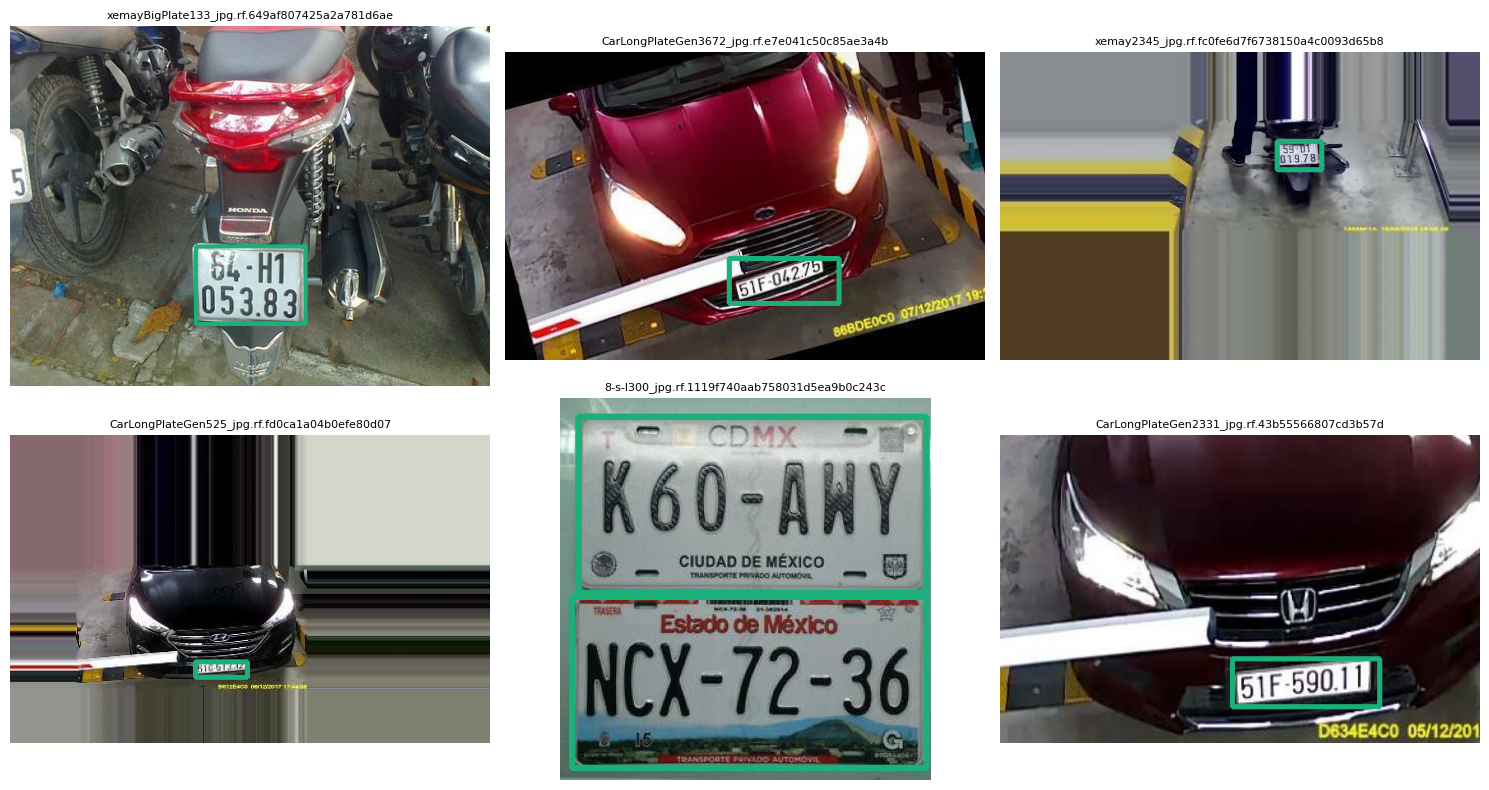

In [ ]:
# 1.2 · Análisis exploratorio del dataset de detección
SIZE_LIMITS = (32 ** 2, 96 ** 2)  # área en píxeles: pequeña < 32², mediana < 96², grande ≥ 96² (criterio COCO)


def label_path_for(image_path: Path) -> Path:
    """.../<split>/images/x.jpg → .../<split>/labels/x.txt (convención YOLO)."""
    parts = list(Path(image_path).parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    return Path(*parts[:i], "labels", *parts[i + 1:]).with_suffix(".txt")


def read_yolo_labels(label_path: Path, width: int, height: int) -> sv.Detections:
    """Etiquetas YOLO (caja o polígono, coordenadas normalizadas) → sv.Detections en píxeles."""
    boxes, classes = [], []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) < 5:
                continue
            coords = np.array(values[1:], dtype=float)
            if len(coords) == 4:  # cx cy w h
                cx, cy, bw, bh = coords
                x1, y1, x2, y2 = cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2
            else:  # polígono → caja envolvente
                x1, y1, x2, y2 = coords[0::2].min(), coords[1::2].min(), coords[0::2].max(), coords[1::2].max()
            boxes.append([x1 * width, y1 * height, x2 * width, y2 * height])
            classes.append(int(float(values[0])))
    if not boxes:
        return sv.Detections.empty()
    return sv.Detections(xyxy=np.array(boxes, dtype=float), class_id=np.array(classes, dtype=int))


def count_labels(image_paths) -> tuple:
    """(placas etiquetadas, imágenes sin placa) de una lista de imágenes."""
    boxes = empty = 0
    for path in image_paths:
        label = label_path_for(path)
        n = sum(1 for line in label.read_text().splitlines() if line.strip()) if label.exists() else 0
        boxes, empty = boxes + n, empty + (n == 0)
    return boxes, empty


split_rows = []
for key in ("train", "val", "test"):
    images = list_images(Path(DATA["path"]) / DATA[key])
    boxes, empty = count_labels(images)
    split_rows.append({"split": key, "imágenes": len(images), "placas": boxes, "imágenes sin placa": empty})
display(pd.DataFrame(split_rows).set_index("split"))

test_images = list_images(Path(DATA["path"]) / DATA["test"])
areas = []
for path in test_images:
    width, height = Image.open(path).size
    areas.extend(read_yolo_labels(label_path_for(path), width, height).area.tolist())
areas = np.array(areas)
size_counts = {
    "pequenas": int((areas < SIZE_LIMITS[0]).sum()),
    "medianas": int(((areas >= SIZE_LIMITS[0]) & (areas < SIZE_LIMITS[1])).sum()),
    "grandes": int((areas >= SIZE_LIMITS[1]).sum()),
}
print("Placas en test por tamaño:", size_counts)
(RESULTS_DIR / "dataset_resumen.json").write_text(json.dumps({"splits": split_rows, "test_por_tamano": size_counts}, indent=2))

train_images = list_images(Path(DATA["path"]) / DATA["train"])
sample = random.Random(SEED).sample(train_images, min(6, len(train_images)))
annotator = sv.BoxAnnotator(color=sv.Color.from_hex("#1baf7a"), thickness=3)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, path in zip(axes.flat, sample):
    image = cv2.imread(str(path))
    height, width = image.shape[:2]
    annotated = annotator.annotate(image.copy(), read_yolo_labels(label_path_for(path), width, height))
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(path.name[:45], fontsize=8)
plt.tight_layout()
plt.show()

### 1.3 Datos de lectura: SAVH Guayaquil

`savh_ground_truth_subset.zip`, en la carpeta de Drive, tiene 739 recortes de placa de SAVH Guayaquil: 472 en `placa_legible/` y 267 en `placa_no_legible/`, copiados sin cambios de las 2000 imágenes del dataset público (capturas del 7, 8 y 11 de junio de 2026). `ground_truth.csv` toma la placa del nombre de cada archivo.

**Esa placa no es una transcripción manual: es la lectura automática de la cámara Dahua.** Lo muestran sus errores: 142 de las 472 placas legibles (30 %) no siguen el formato ecuatoriano, y en la imagen la placa se lee bien (`GSO-7335` aparece como `GS07335`, `GTN-8737` como `6TN8737`, `PBT-2437` como `JPBT2437`). Además, 73 imágenes son copias idénticas de otras (43 grupos; quedan 666 únicas, 399 de ellas legibles) y las 267 no legibles también traen texto, que no se puede comprobar mirando la imagen.

Por eso SAVH se usa en varios pasos del notebook:

1. **Extraer el subconjunto** (la celda siguiente).
2. **Armar la referencia corregida** con la revisión de placas y marcar los duplicados (sección 2.2).
3. **Leer cada imagen única con fast-plate-ocr** y estudiar la confianza del OCR (sección 4.3).
4. **Calcular EMR y CER** sobre las legibles únicas, por estado de la referencia, con la ablación de la normalización (sección 5.4).
5. **Evaluar la regla de decisión** con una lista simulada de placas autorizadas (sección 5.5).

`SAVH_SAMPLE_SIZE` permite probar con una muestra chica de legibles. Si no encuentra el `.zip`, todo lo de SAVH se salta sin romper el resto del notebook.


In [ ]:
# 1.3 · Extrae los recortes de SAVH Guayaquil (una vez por sesión, en el disco local de Colab)
_missing = [name for name in ("WORK_DIR", "OCR_RESULTS_DIR", "SAVH_ZIP_CANDIDATES") if name not in globals()]
if _missing:
    raise RuntimeError("Faltan variables de celdas anteriores: " + ", ".join(_missing) + ". En una sesión nueva, "
                       "corre primero la sección 0 completa.")

SAVH_DIR = Path("/content/savh_ground_truth_subset")  # disco local de Colab: se extrae en cada sesión
SAVH_SAMPLE_SIZE = None  # p. ej. 50 para una prueba rápida con legibles; None = todas las imágenes únicas (4.3 y 5.4)

savh_zip = next((p for p in SAVH_ZIP_CANDIDATES if p.exists()), None)
if not (SAVH_DIR / "ground_truth.csv").exists() and savh_zip:
    with zipfile.ZipFile(savh_zip) as archive:
        archive.extractall(SAVH_DIR)

savh_gt = None
if (SAVH_DIR / "ground_truth.csv").exists():
    savh_gt = pd.read_csv(SAVH_DIR / "ground_truth.csv", dtype=str, keep_default_na=False)
    savh_gt.insert(0, "fila_gt", range(1, len(savh_gt) + 1))  # fila de datos: la misma numeración de la hoja de revisión
    print(f"{len(savh_gt)} recortes en {SAVH_DIR}")
    display(savh_gt["folder"].value_counts())
else:
    print("Aviso: no se encontró savh_ground_truth_subset.zip en la carpeta de Drive ni en /content; se salta SAVH.")

739 recortes en /content/savh_ground_truth_subset


,count
folder,
legible,472
no_legible,267
